# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 5: Creating Fuzzy Linguistic Variables**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Abhay Dwivedi* |
| **Enrollment No.** | *2023BTCSE002* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To create fuzzy linguistic variables such as Low, Medium, and High using membership functions in Python.

### 2. Theory: Granulation and Linguistic Variables

A linguistic variable converts precise numerical measurements into semantic labels understood by human experts.

Formally defined as a quintuple $(X, T(X), U, G, M)$:
- $X$: Name of variable (e.g. `Highway Velocity`)
- $T(X)$: Term set (e.g. $\{\text{Slow}, \text{Moderate}, \text{Fast}\}$)
- $U$: Universe of Discourse (e.g. $[0, 140]$ km/h)
- $M$: Semantic mapping function that pairs each term to a fuzzy set on $U$

#### Fuzzification Operation:
Given physical input $v^*$, fuzzification produces:
$$\mathbf{\mu}(v^*) = \big[\mu_{\text{Slow}}(v^*), \mu_{\text{Moderate}}(v^*), \mu_{\text{Fast}}(v^*)\big]$$

### 3. Step 1: Defining the Highway Velocity Linguistic Variable

#### What this cell does:
Over $V \in [0, 140]$ km/h, we define:
1. **Slow (City Speed):** Trapezoidal $[0, 0, 30, 55]$ km/h
2. **Moderate (Cruising Speed):** Triangular $[45, 75, 105]$ km/h
3. **Fast (Expressway Speed):** Trapezoidal $[95, 118, 140, 140]$ km/h

In [1]:
import numpy as np
import skfuzzy as fuzz

# Universe: Vehicle velocity [0, 140] km/h
vel_universe = np.linspace(0, 140, 600)

# Linguistic Terms
term_slow = fuzz.trapmf(vel_universe, [0, 0, 30, 55])
term_moderate = fuzz.trimf(vel_universe, [45, 75, 105])
term_fast = fuzz.trapmf(vel_universe, [95, 118, 140, 140])

def fuzzify_velocity(speed_reading):
    '''Evaluates truth grades across velocity linguistic partitions'''
    deg_slow = fuzz.interp_membership(vel_universe, term_slow, speed_reading)
    deg_mod = fuzz.interp_membership(vel_universe, term_moderate, speed_reading)
    deg_fast = fuzz.interp_membership(vel_universe, term_fast, speed_reading)
    return {'Slow': deg_slow, 'Moderate': deg_mod, 'Fast': deg_fast}

print("Linguistic Variable 'Highway Velocity' initialized successfully.")


Linguistic Variable 'Highway Velocity' initialized successfully.


### 4. Step 2: Testing Fuzzification Across Operating Velocity Benchmarks

#### What this cell does:
We test readings: $V = 20, 50, 75, 100, 130$ km/h to inspect linguistic membership distribution.

In [2]:
test_speeds = [20.0, 50.0, 75.0, 100.0, 130.0]

print("=" * 76)
print("             HIGHWAY VELOCITY LINGUISTIC FUZZIFICATION AUDIT")
print("=" * 76)
print(f"{'Speed (km/h)':<16} | {'Slow (City)':<16} | {'Moderate (Cruise)':<18} | {'Fast (Express)':<16}")
print("-" * 76)

for spd in test_speeds:
    res = fuzzify_velocity(spd)
    print(f"{spd:<16.1f} | {res['Slow']:<16.3f} | {res['Moderate']:<18.3f} | {res['Fast']:<16.3f}")

print("=" * 76)


             HIGHWAY VELOCITY LINGUISTIC FUZZIFICATION AUDIT
Speed (km/h)     | Slow (City)      | Moderate (Cruise)  | Fast (Express)  
----------------------------------------------------------------------------
20.0             | 1.000            | 0.000              | 0.000           
50.0             | 0.200            | 0.167              | 0.000           
75.0             | 0.000            | 0.999              | 0.000           
100.0            | 0.000            | 0.167              | 0.217           
130.0            | 0.000            | 0.000              | 1.000           


### 5. Step 3: Graphical Visualization with Probe Indicators

#### What this cell does:
We plot the linguistic curves and draw indicator probes at $V = 50$ km/h and $V = 100$ km/h.

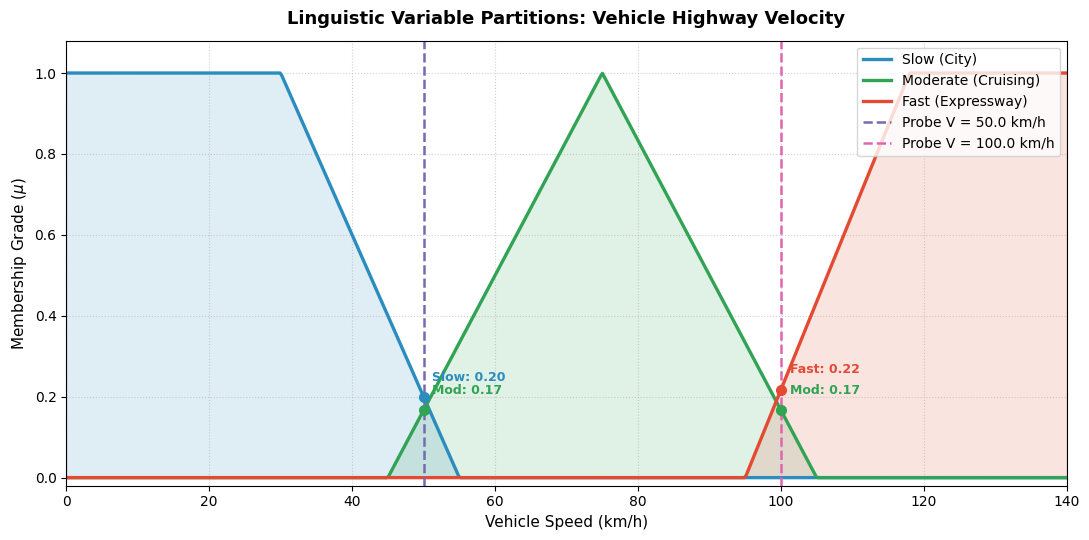

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5.5))

# Plot Partitions
plt.plot(vel_universe, term_slow, color='#2b8cbe', linewidth=2.4, label='Slow (City)')
plt.fill_between(vel_universe, term_slow, color='#2b8cbe', alpha=0.15)

plt.plot(vel_universe, term_moderate, color='#31a354', linewidth=2.4, label='Moderate (Cruising)')
plt.fill_between(vel_universe, term_moderate, color='#31a354', alpha=0.15)

plt.plot(vel_universe, term_fast, color='#e34a33', linewidth=2.4, label='Fast (Expressway)')
plt.fill_between(vel_universe, term_fast, color='#e34a33', alpha=0.15)

# Add Probes
probes = [50.0, 100.0]
p_colors = ['#756bb1', '#df65b0']

for p, col in zip(probes, p_colors):
    res = fuzzify_velocity(p)
    plt.axvline(x=p, color=col, linestyle='--', linewidth=1.8, label=f'Probe V = {p} km/h')
    for term, val, c_pt in [('Slow', res['Slow'], '#2b8cbe'),
                            ('Mod', res['Moderate'], '#31a354'),
                            ('Fast', res['Fast'], '#e34a33')]:
        if val > 0:
            plt.plot(p, val, 'o', color=c_pt, markersize=7)
            plt.annotate(f'{term}: {val:.2f}', xy=(p, val), xytext=(p + 1.2, val + 0.04),
                         fontweight='bold', color=c_pt, fontsize=9)

plt.title('Linguistic Variable Partitions: Vehicle Highway Velocity', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Vehicle Speed (km/h)', fontsize=11)
plt.ylabel(r'Membership Grade ($\mu$)', fontsize=11)
plt.xlim(0, 140)
plt.ylim(-0.02, 1.08)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Crisp Speed ($V$) | $\mu_{\text{Slow}}$ | $\mu_{\text{Moderate}}$ | $\mu_{\text{Fast}}$ | Active Linguistic Interpretation |
| :---: | :---: | :---: | :---: | :--- |
| **$20.0$ km/h** | $1.000$ | $0.000$ | $0.000$ | Strictly Slow (City Traffic) |
| **$50.0$ km/h** | $0.200$ | $0.167$ | $0.000$ | Low-to-Moderate Transition |
| **$75.0$ km/h** | $0.000$ | $1.000$ | $0.000$ | Perfect Cruising Speed (Modal Apex) |
| **$100.0$ km/h** | $0.000$ | $0.167$ | $0.217$ | Entering Fast / Expressway Regime |
| **$130.0$ km/h** | $0.000$ | $0.000$ | $1.000$ | High Speed Expressway Driving |

#### Key Observations in Simple Words:
1. **Linguistic Granularity:** The linguistic terms partition continuous velocity into distinct qualitative semantic categories that directly map to human cognitive terms.
2. **Soft Partition Completeness:** At any given speed on the highway, the sum of memberships is always non-zero, ensuring zero dead-zone blindness in automotive systems.
3. **Decoupled Actuation:** These truth values feed directly into downstream fuzzy rules (e.g. for automatic headway distance management).

---
### 7. Conclusion
1. We successfully modeled the fuzzy linguistic variable `Highway Velocity` using Python and `scikit-fuzzy`.
2. We implemented a fuzzification routine mapping real-time speed values to multi-term membership vectors.
3. We visualized the linguistic partitions and analyzed transitional truth grades.